<a href="https://colab.research.google.com/github/srishanthgouda/micrograd-autograd-engine/blob/main/Micrograd_scratchpad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Welcome to Colab!

In [107]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import random

In [108]:
def f(x):
  return 3*x**2-4*x+5

In [109]:
f(3.0)

20.0

In [110]:
xs=np.arange(-5, 5, 0.25)
xs

array([-5.  , -4.75, -4.5 , -4.25, -4.  , -3.75, -3.5 , -3.25, -3.  ,
       -2.75, -2.5 , -2.25, -2.  , -1.75, -1.5 , -1.25, -1.  , -0.75,
       -0.5 , -0.25,  0.  ,  0.25,  0.5 ,  0.75,  1.  ,  1.25,  1.5 ,
        1.75,  2.  ,  2.25,  2.5 ,  2.75,  3.  ,  3.25,  3.5 ,  3.75,
        4.  ,  4.25,  4.5 ,  4.75])

In [111]:
ys=f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

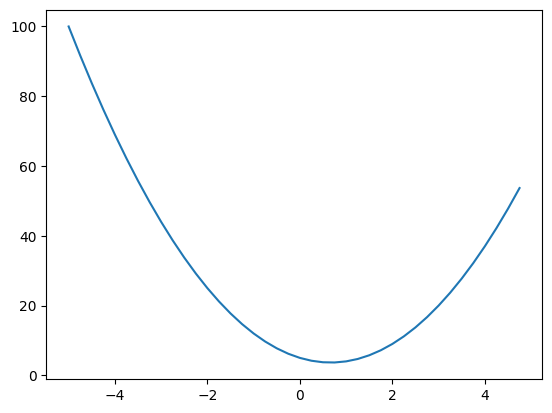

In [112]:
plt.plot(xs, ys)

In [113]:
h=0.0000000001    #derivative
x=3
(f(x+h)-f(x))/h

14.000001158365194

In [114]:
a=2.0
b=-3.0
c=10.0
d=a*b+c
print(d)

4.0


In [115]:
h=0.00001
#checking the grad a of d
d1=a*b+c
a+=h
d2=a*b+c
print(d1)
print(d2)
print((d2-d1)/h)


4.0
3.9999699999999994
-3.000000000064062


In [116]:
h=0.00001
#checking the grad b of d
d1=a*b+c
b+=h
d2=a*b+c
print(d1)
print(d2)
print((d2-d1)/h)

3.9999699999999994
3.9999900000999995
2.00001000001393


In [117]:
h=0.00001
#checking the grad c of d
d1=a*b+c
c+=h
d2=a*b+c
print(d1)
print(d2)
print((d2-d1)/h)

3.9999900000999995
4.000000000099999
0.9999999999621422


In [118]:
class Value:
  def __init__(self, data,  _children=(),_op='', label=''):
    self.data=data
    self.grad=0.0
    self._prev=set(_children)
    self._op=_op
    self.label=label
    self._backward=lambda:None

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other=other if isinstance(other, Value) else Value(other)
    out= Value(self.data+other.data, (self, other), '+')
    def _backward():
      self.grad+=1.0*out.grad
      other.grad+=1.0*out.grad
    out._backward=_backward
    return out

  def __mul__(self, other):
    other=other if isinstance(other, Value) else Value(other)
    out= Value(self.data*other.data, (self, other), '*')
    def _backward():
      self.grad+=other.data*out.grad
      other.grad+=self.data*out.grad
    out._backward=_backward
    return out

  def __rmul__(self, other):
    return self*other

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers"
    out=Value(self.data**other, (self, ), f'**{other}')
    def _backward():
      self.grad+=other*(self.data**(other-1))*out.grad
    out._backward=_backward
    return out

  def __truediv__(self, other):
    return self*other**-1

  def __sub__(self, other):
    return self+other*-1

  def tanh(self):
    e=math.exp(2*self.data)
    t=(e-1)/(e+1)
    out= Value(t, (self, ), 'tanh')
    def _backward():
      self.grad+=(1-t**2)*out.grad
    out._backward=_backward
    return out

  def exp(self):
    x=self.data
    out=Value(math.exp(x), (self, ), 'exp')

    def _backward():
      self.grad+=out.data*out.grad
    out._backward=_backward

    return out


  def backward(self):

    topo=[]
    visited=set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad=1.0
    for node in reversed(topo):
      node._backward()

a=Value(2.0, label='a')
b=Value(3.0, label='b')
c=Value(10.0, label='c')
e=a*b
e.label='e'
d=e+c
d.label='d'

f=Value(-2.0, label='f')
l=f*d
l.label='l'

print(d._prev)
print(d._op)

{Value(data=6.0), Value(data=10.0)}
+


In [119]:
from graphviz import Digraph

def trace(root):
  nodes, edges = set(), set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child, v))
        build(child)

  build(root)
  return nodes, edges

def draw_dot(root):
  dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

  nodes, edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label = "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad),shape='record')
    if n._op:
      # if this value is a result of some operation, create an op node for it
      dot.node(name = uid + n._op, label = n._op)
      # and connect this node to it
      dot.edge(uid + n._op, uid)

  for n1, n2 in edges:
    # connect n1 to the op node of n2
    dot.edge(str(id(n1)), str(id(n2)) + n2._op)
  return dot


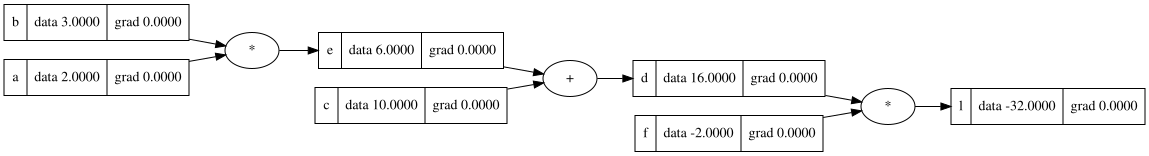

In [120]:
draw_dot(l)

In [121]:
def func():
  h=0.00001

  a=Value(2.0, label='a')
  b=Value(3.0, label='b')
  c=Value(10.0, label='c')
  e=a*b
  e.label='e'
  d=e+c
  d.label='d'

  f=Value(-2.0, label='f')
  l=f*d
  l.label='l'
  L1=l.data

  h=0.00001

  a=Value(2.0, label='a')
  b=Value(3.0+h, label='b')
  c=Value(10.0, label='c')
  e=a*b
  e.label='e'
  d=e+c
  d.label='d'

  f=Value(-2.0, label='f')
  l=f*d
  l.label='l'
  L2=l.data

  print((L2-L1)/h)

In [122]:
func()

-3.9999999998485687


In [123]:
f.grad=16
d.grad=-2.0
l.grad=1.0
e.grad=-2
c.grad=-2
a.grad=-6
b.grad=-4

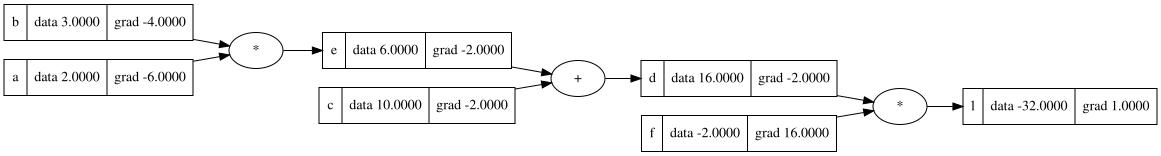

In [124]:
draw_dot(l)

In [125]:
a.data+=0.001*a.grad
b.data+=0.001*b.grad
c.data+=0.001*c.grad
f.data+=0.001*f.grad
#this increases f, (makes it less negative || more positive)
e=a*b
d=e+c
l=f*d
print(l.data)

-31.688495615999997


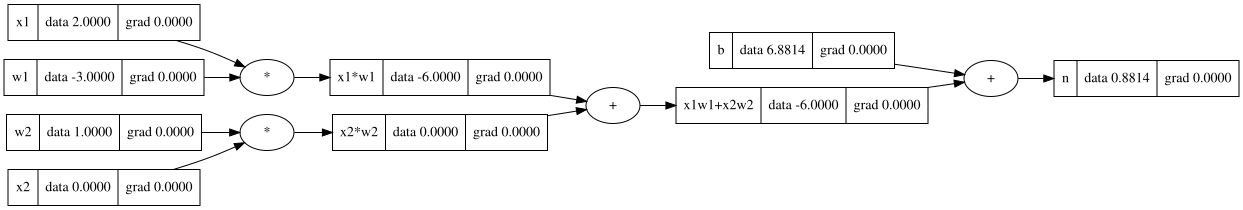

In [126]:
#inputs x1 and x2
x1=Value(2.0, label='x1')
x2=Value(0.0, label='x2')
#weights of x1 and x2
w1=Value(-3.0, label='w1')
w2=Value(1.0, label='w2')
#bias of the neuron
b=Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1*w1'
x2w2=x2*w2; x2w2.label='x2*w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1+x2w2'
n=x1w1x2w2+b; n.label='n'

draw_dot(n)

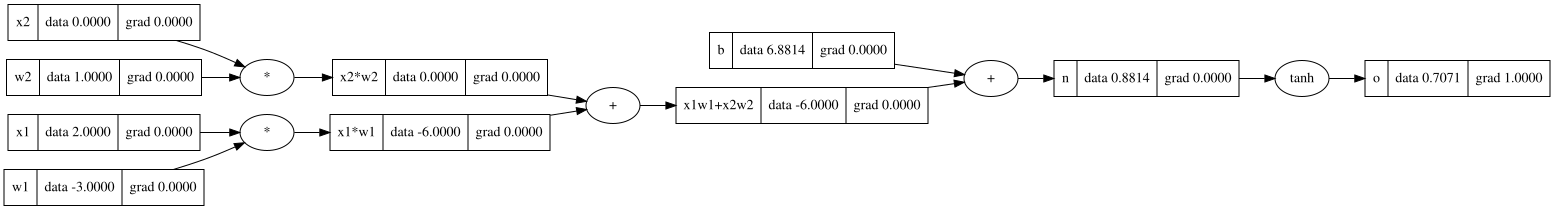

In [127]:
o=n.tanh() ; o.label='o'   #assume tanh as an activation function we use in an nn model
o.grad=1.0
draw_dot(o)

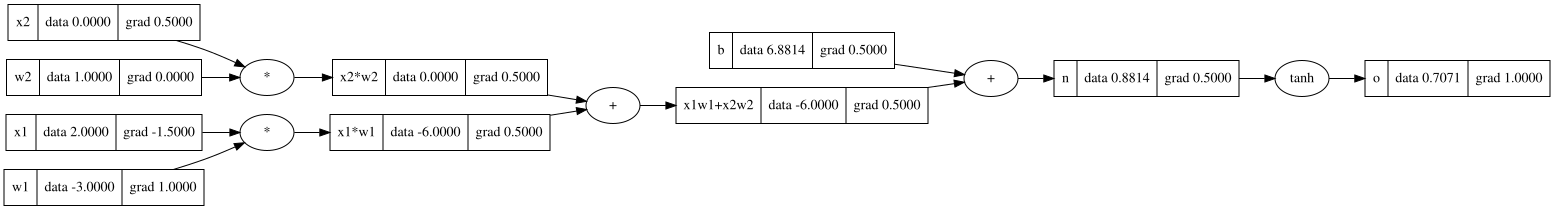

In [128]:
n.grad=0.5    #(1-0.7071**2) which comes from do/dn=1-n**2
x1w1x2w2.grad=1.0*n.grad # due to +,, the grads are the same for n and x1w1x2w2
x1w1.grad=1.0*x1w1x2w2.grad   #due the +, the grads are same for x1w1, x2w2 and x1w1x2w2
x2w2.grad=1.0*x1w1x2w2.grad

x1.grad=w1.data*x1w1.grad
w1.grad=x1.data*x1w1.grad
x2.grad=w2.data*x2w2.grad
w2.grad=x2.data*x2w2.grad
b.grad=1.0*n.grad
draw_dot(o)

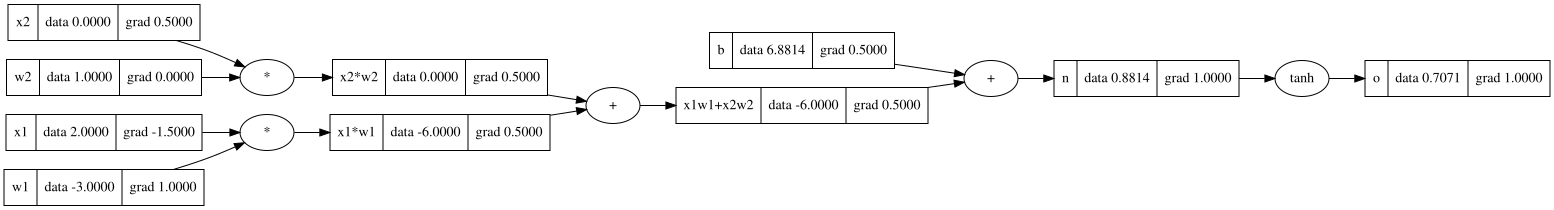

In [129]:
#now after setting all the grads to 0, we call ._backward() func.
o._backward()   #backpropagating through o
draw_dot(o)

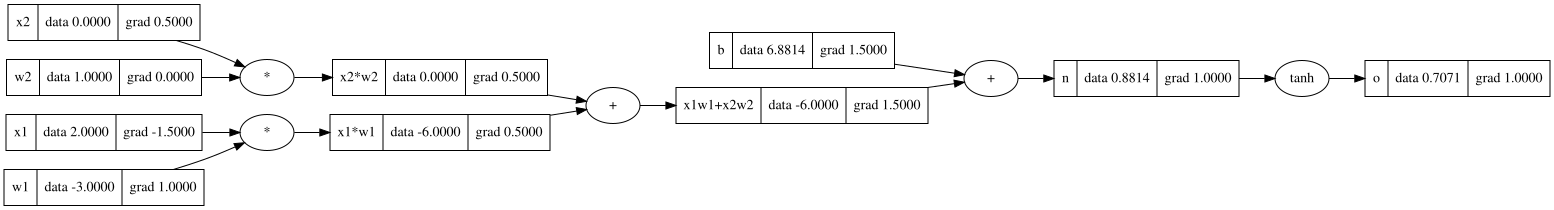

In [130]:
n._backward()
draw_dot(o)

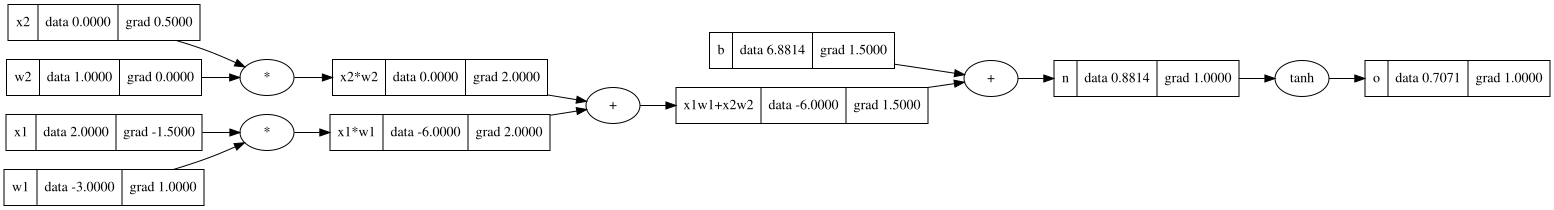

In [131]:
x1w1x2w2._backward()
draw_dot(o)

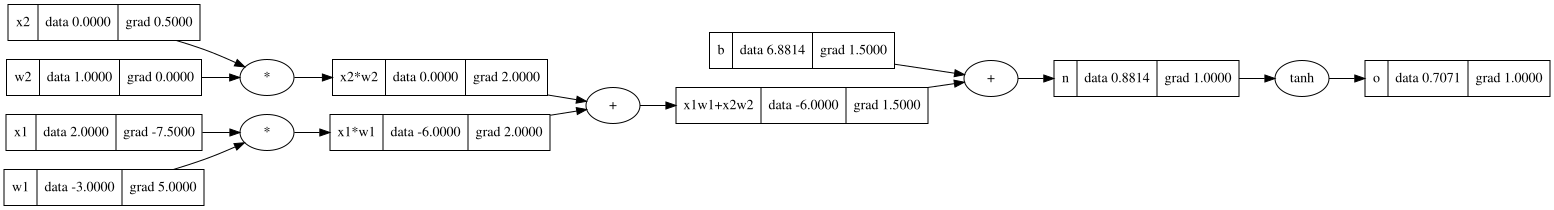

In [132]:
x1w1._backward()
draw_dot(o)

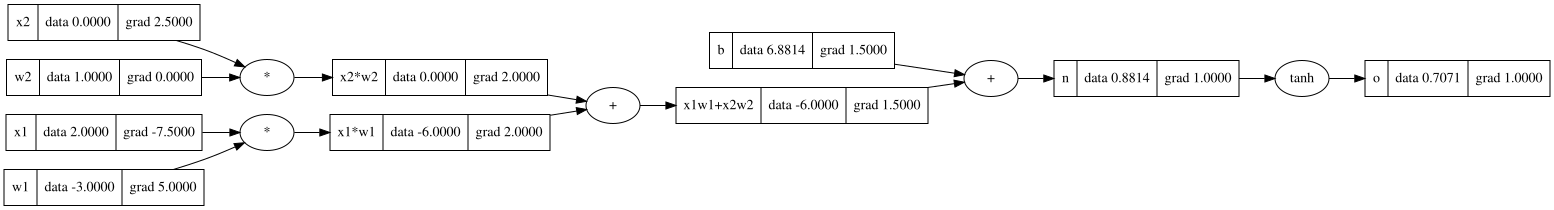

In [133]:
x2w2._backward()
draw_dot(o)

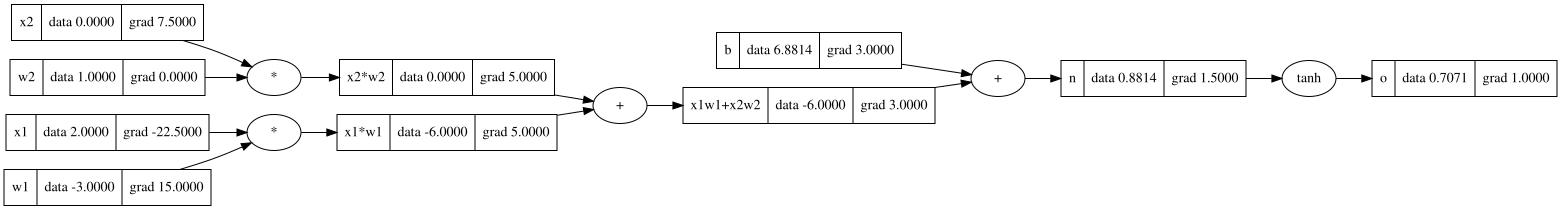

In [134]:
#building topological order to get rid of manual ._backward() calling.

o.grad=1.0

topo=[]
visited=set()
def build_topo(v):
  if v not in visited:
    visited.add(v)
    for child in v._prev:
      build_topo(child)
    topo.append(v)
build_topo(o)


for node in reversed(topo):
  node._backward()

draw_dot(o)

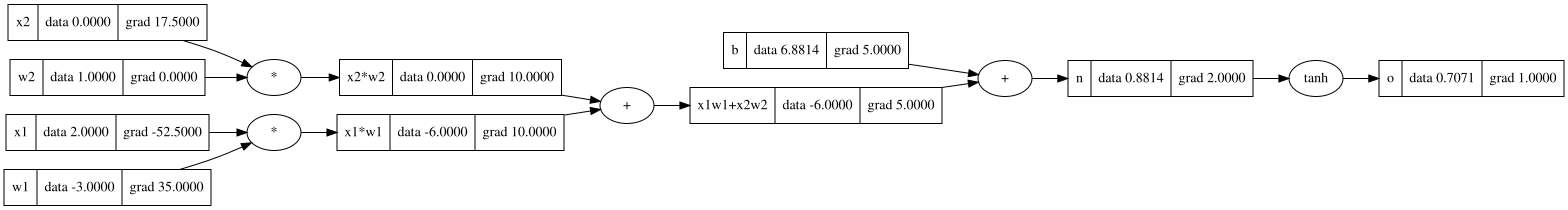

In [135]:
# by adding this topo code inside the value class as a function,
# we can now do backprop in one go
o.backward()
draw_dot(o)

In [136]:
#made a change in the Value class. Added += operator instead of just = while storing the gradients of self and other inside each operation function. cause when we have variables like,
#a=value(2.0)
#b=a+a
#it assumes one as 'self' and second as 'other', and stores grad=1 inside each. but as they both are same objects, it just stores1, where it shouldve stored 2.

In [137]:
#when we do
#a=value(2.0)
#a+1      we come to see an error because, the + operation triggers _add_ func inside the class, where it tries to access a.data and 1.data. as 1.data is not possible, we get an error.
#so to solve this, we made a change inside the operation functions in Value class.

In [138]:
#similarly , it applies to multiplication too. so we make the same changes.
#but in multiplication, while doing a*2 where a is a Value object and 2 is int , it goes right. but doing 2*a triggers error. because, 2 is an int , and python has no clue what to do when * is called , because it is defined inside a value class and only a value object can access it.
# so to over come it , we add an __rmul__ function. So when we call 2*a, it fails to run, and python return NotImplemented, then after reading the Value object a, it triggers the reverse multiplication function inside the value class. Which returns a*2 (as multiplication is commutative), which calls the regular __mul___ function.

In [139]:
#built other arithmetic operations like subtraction, power, division , inside the class.


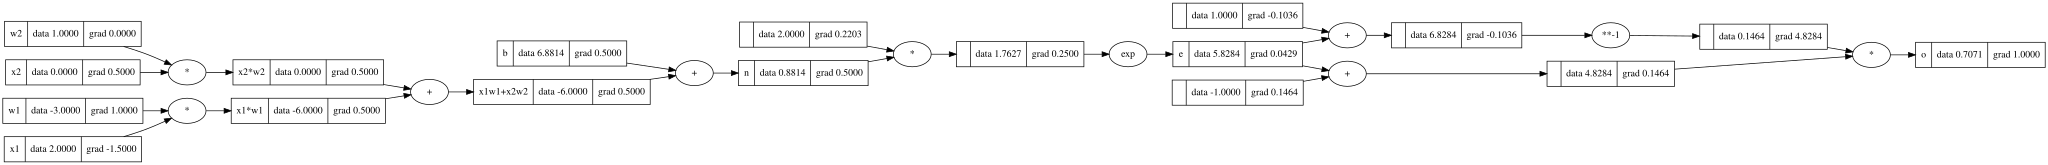

In [140]:

#inputs x1 and x2
x1=Value(2.0, label='x1')
x2=Value(0.0, label='x2')
#weights of x1 and x2
w1=Value(-3.0, label='w1')
w2=Value(1.0, label='w2')
#bias of the neuron
b=Value(6.8813735870195432, label='b')

x1w1=x1*w1; x1w1.label='x1*w1'
x2w2=x2*w2; x2w2.label='x2*w2'
x1w1x2w2=x1w1+x2w2; x1w1x2w2.label='x1w1+x2w2'
n=x1w1x2w2+b; n.label='n'
e=(2*n).exp()
e.label='e'
o=(e-1)/(e+1)
o.label='o'
o.backward()
draw_dot(o)

In [141]:
class Neuron:
  def __init__(self, nin):
    self.w=[Value(random.uniform(-1, 1)) for _ in range(nin)]
    self.b=Value(random.uniform(-1, 1))

  def __call__(self, x):
      act =sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
      out=act.tanh()
      return out

  def parameters(self):
    return self.w+[self.b]


class Layer:

  def __init__(self, nin, nout):
    self.neurons=[Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs=[n(x) for n in self.neurons]
    return outs[0] if len(outs)==1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]


class MLP:
  def __init__(self, nin, nouts):
    sz=[nin]+nouts
    self.layers=[Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x=layer(x)

    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]




In [142]:
n=MLP(3, [4, 4, 1])

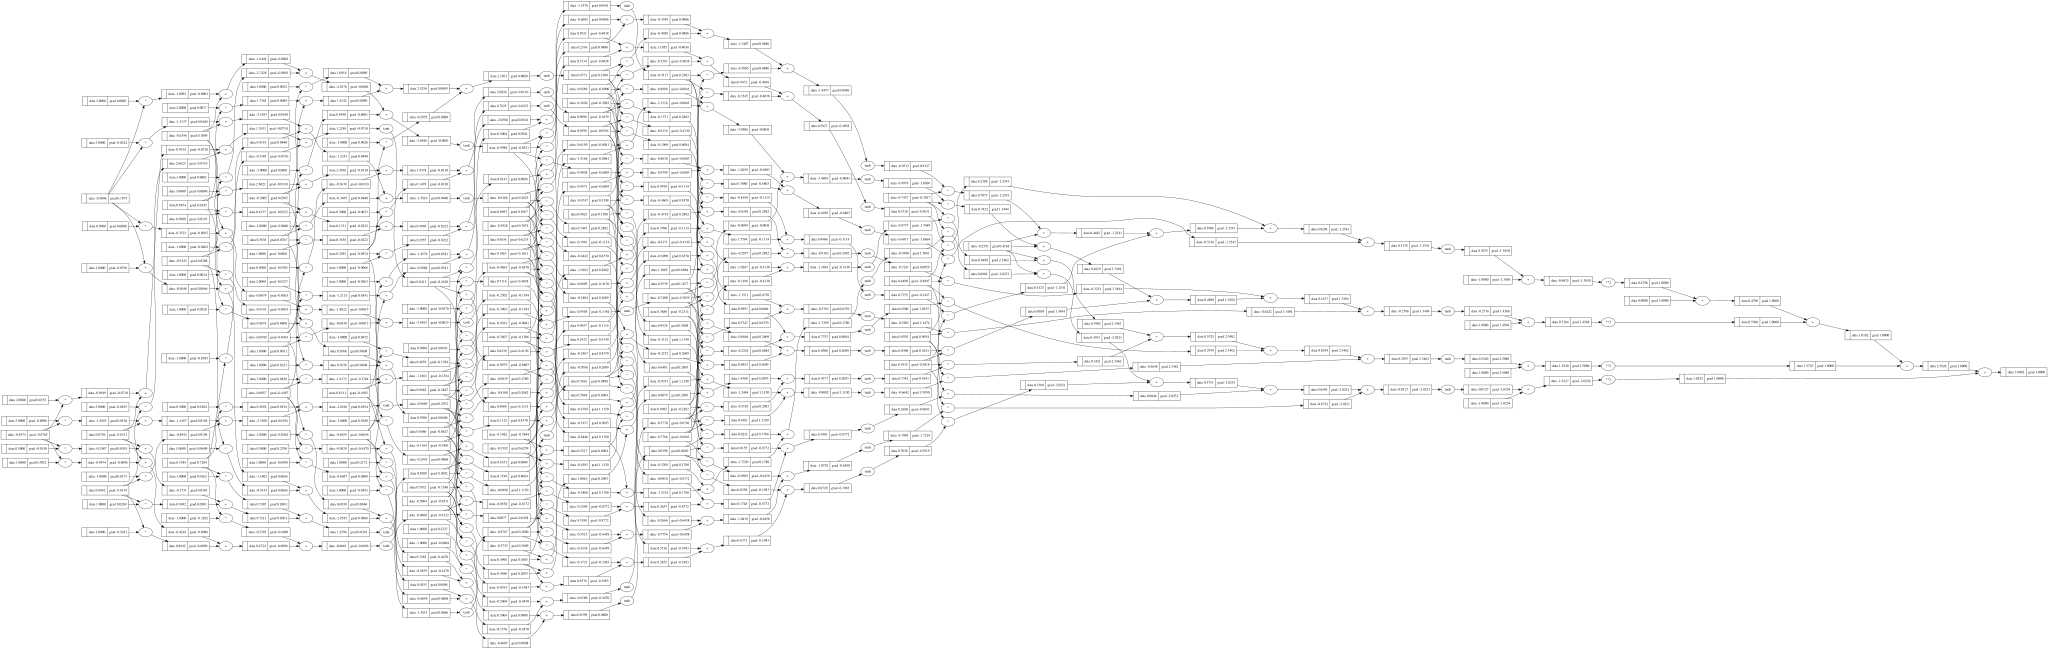

In [143]:
xs=[[2.0, 3.0, -1.0], [3.0, -1.0, 0.5], [0.5, 1.0, 1.0], [1.0, 1.0, -1.0]]
ys=[1.0, -1.0, -1.0, 1.0]

ypred=[n(x) for x in xs]

loss=sum(((ygt-yout)**2 for yout , ygt in zip(ys, ypred)), Value(0.0))

loss.backward()
draw_dot(loss)

In [199]:
for p in n.parameters():
  p.data-=0.01*p.grad

In [200]:
ypred=[n(x) for x in xs]

loss=sum(((ygt-yout)**2 for yout , ygt in zip(ys, ypred)), Value(0.0))

loss.backward()
loss

Value(data=0.012078359479228895)

In [201]:
ypred

[Value(data=0.967048544328778),
 Value(data=-0.9187674619697073),
 Value(data=-0.9468912315234765),
 Value(data=0.9603352231262994)]

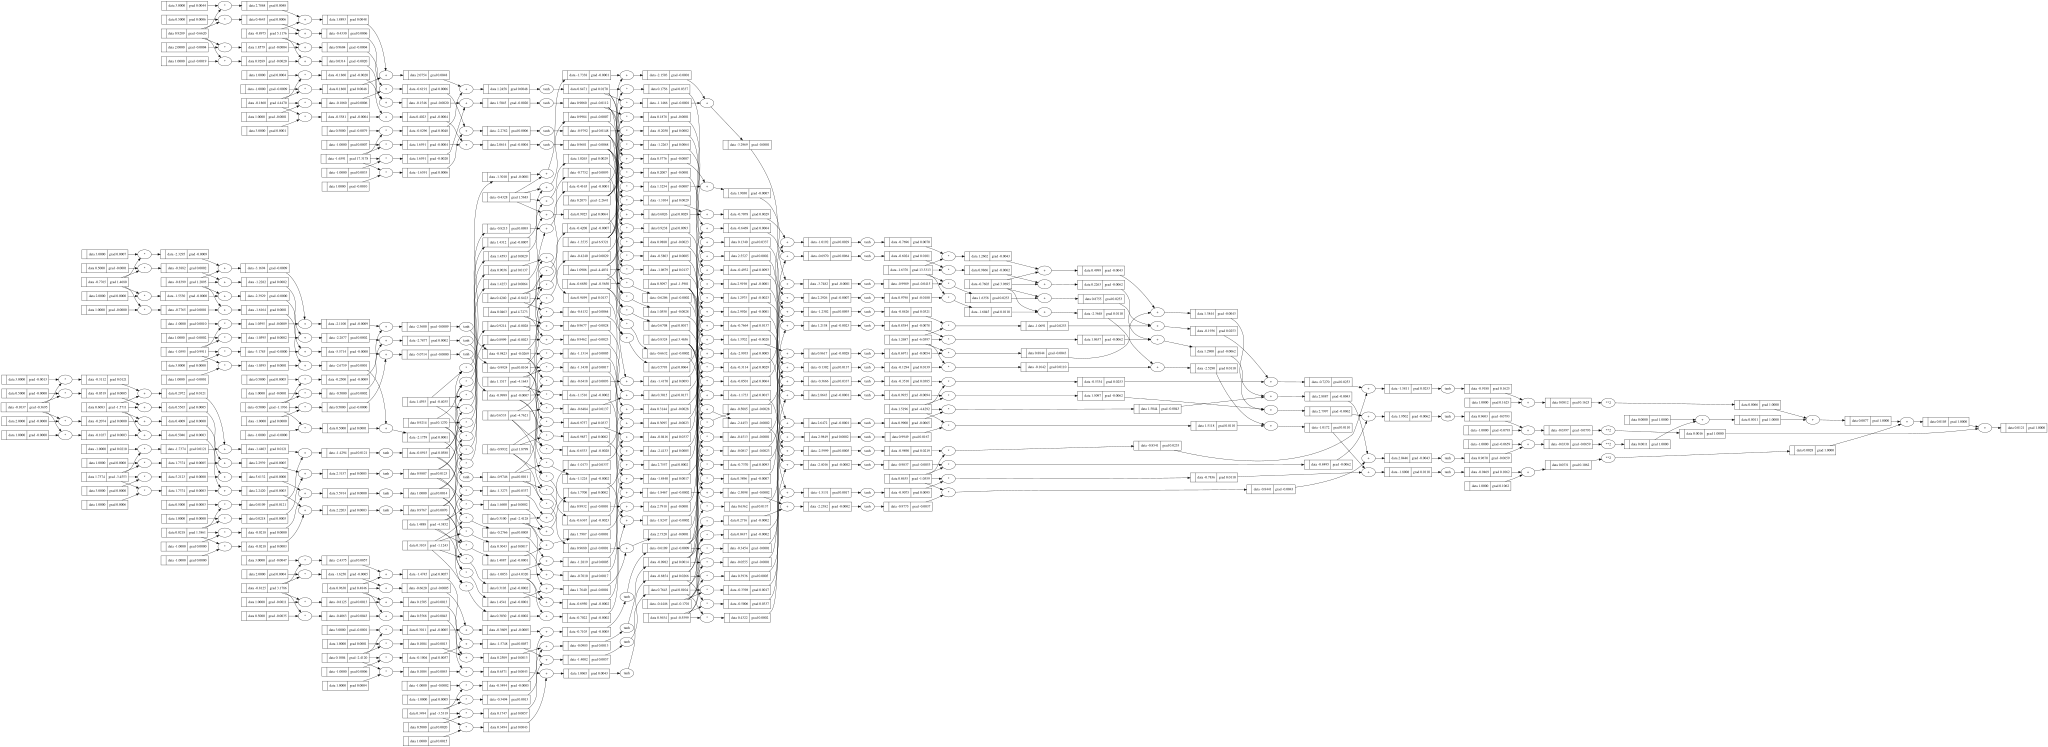

In [202]:
draw_dot(loss)